In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings('ignore')

In [21]:
url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/main/online_shoppers_intention.csv"
df = pd.read_csv(url)

print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores nulos totales: {df.isna().sum().sum()}")

Dimensiones del dataset: 12330 filas x 18 columnas
Valores nulos totales: 0


In [22]:
print("\nDistribución de Revenue (%):")
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))
df.head(3)


Distribución de Revenue (%):
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False


In [23]:
# Creamos un DataFrame vacío de tipo booleano para nuestra matriz transaccional
df_trans = pd.DataFrame(index=df.index)

In [33]:
# Variable Objetivo: Compra vs No Compra
df_trans['Compro_True'] = (df['Revenue'] == True)
df_trans['NoCompro_False'] = (df['Revenue'] == False)

In [25]:
# Variable de negocio clave: ¿Visitó página con valor comercial (PageValues > 0)?
df_trans['PaginaValor_Si'] = (df['PageValues'] > 0)
df_trans['PaginaValor_Cero'] = (df['PageValues'] == 0)

In [26]:
# Cantidad de páginas de producto visitadas
df_trans['Productos_Pocos(0-5)'] = (df['ProductRelated'] <= 5)
df_trans['Productos_Medio(6-25)'] = (df['ProductRelated'] > 5) & (df['ProductRelated'] <= 25)
df_trans['Productos_Muchos(>25)'] = (df['ProductRelated'] > 25)

In [27]:
# Tiempo invertido en páginas de producto (en segundos)
df_trans['TiempoProd_Corto(<1min)'] = (df['ProductRelated_Duration'] <= 60)
df_trans['TiempoProd_Medio(1-10min)'] = (df['ProductRelated_Duration'] > 60) & (df['ProductRelated_Duration'] <= 600)
df_trans['TiempoProd_Largo(>10min)'] = (df['ProductRelated_Duration'] > 600)

In [28]:
# Tasa de rebote y Salida
df_trans['Rebote_Cero'] = (df['BounceRates'] == 0)
df_trans['Rebote_Alto(>0.05)'] = (df['BounceRates'] > 0.05)
df_trans['Salida_Baja(<0.02)'] = (df['ExitRates'] < 0.02)

In [29]:
# Tipo de Visitante y Temporalidad
df_trans['Visitante_Recurrente'] = (df['VisitorType'] == 'Returning_Visitor')
df_trans['Visitante_Nuevo'] = (df['VisitorType'] == 'New_Visitor')
df_trans['FinDeSemana_Si'] = (df['Weekend'] == True)
df_trans['EntreSemana'] = (df['Weekend'] == False)
df_trans['FechaEspecial_Si'] = (df['SpecialDay'] > 0)

In [30]:
# Meses más relevantes
meses_dummies = pd.get_dummies(df['Month'], prefix='Mes').astype(bool)
df_trans = pd.concat([df_trans, meses_dummies], axis=1)

In [31]:
# Principales fuentes de tráfico
for t in [1, 2, 3, 4]:
    df_trans[f'Trafico_Tipo_{t}'] = (df['TrafficType'] == t)

In [32]:
df_trans = df_trans.astype(bool)

print(f"Matriz transaccional lista: {df_trans.shape[0]} sesiones x {df_trans.shape[1]} ítems binarios")
df_trans.head(3)

Matriz transaccional lista: 12330 sesiones x 32 ítems binarios


,Compro_True,NoCompro_False,PaginaValor_Si,PaginaValor_Cero,Productos_Pocos(0-5),Productos_Medio(6-25),Productos_Muchos(>25),TiempoProd_Corto(<1min),TiempoProd_Medio(1-10min),TiempoProd_Largo(>10min),...,Mes_June,Mes_Mar,Mes_May,Mes_Nov,Mes_Oct,Mes_Sep,Trafico_Tipo_1,Trafico_Tipo_2,Trafico_Tipo_3,Trafico_Tipo_4
0,False,True,False,True,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,False
1,False,True,False,True,True,False,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
2,False,True,False,True,True,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False


In [34]:
# Calculamos el soporte individual
soporte_individual = df_trans.mean(axis=0).sort_values(ascending=False)

In [35]:
# Tabla resumen de soporte (%)
df_soporte = pd.DataFrame({
    'Item': soporte_individual.index,
    'Sesiones': df_trans.sum()[soporte_individual.index].values,
    'Soporte (%)': (soporte_individual.values * 100).round(2)
})
display(df_soporte.head(15))

,Item,Sesiones,Soporte (%)
0,Visitante_Recurrente,10551,85.57
1,NoCompro_False,10422,84.53
2,PaginaValor_Cero,9600,77.86
3,EntreSemana,9462,76.74
4,TiempoProd_Largo(>10min),6156,49.93
5,Rebote_Cero,5518,44.75
6,Productos_Medio(6-25),5302,43.00
7,Salida_Baja(<0.02),4675,37.92
8,Productos_Muchos(>25),4659,37.79
9,TiempoProd_Medio(1-10min),4584,37.18


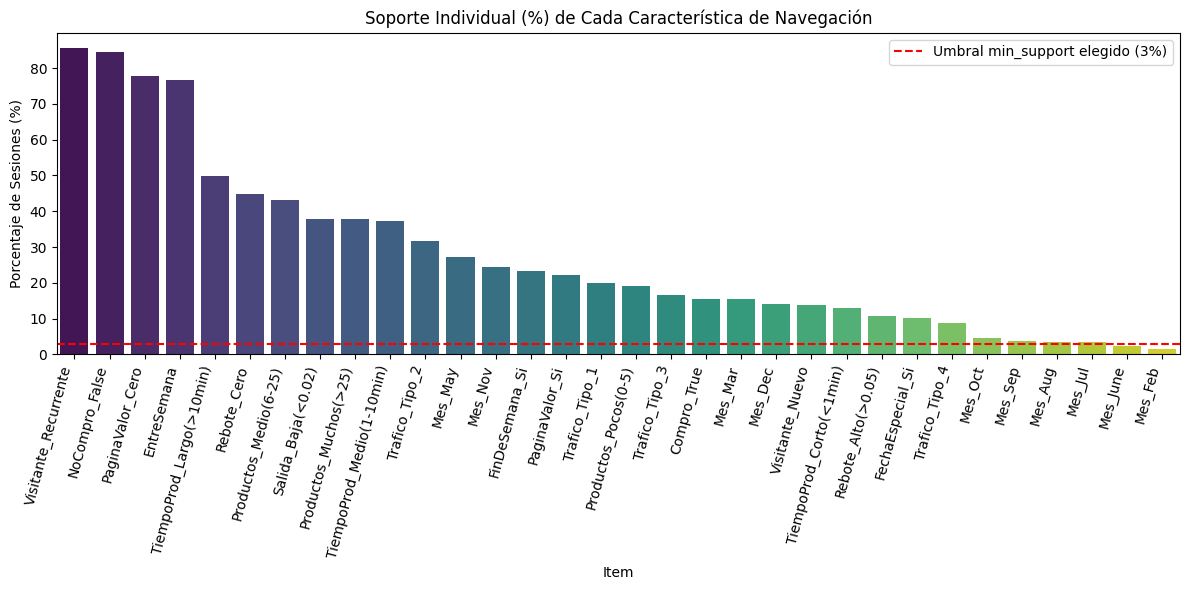

In [37]:
# Gráfica de barras
plt.figure(figsize=(12, 6))
sns.barplot(x='Item', y='Soporte (%)', data=df_soporte, palette='viridis')
plt.axhline(3, color='red', linestyle='--', label='Umbral min_support elegido (3%)')
plt.xticks(rotation=75, ha='right')
plt.title('Soporte Individual (%) de Cada Característica de Navegación')
plt.ylabel('Porcentaje de Sesiones (%)')
plt.legend()
plt.tight_layout()
plt.show()

#Algoritmo Apriori

In [38]:
# Aplicamos Apriori con soporte mínimo del 3% (0.03 -> ~370 sesiones)
min_soporte = 0.03
itemsets = apriori(df_trans, min_support=min_soporte, use_colnames=True, max_len=4)

# Agregamos columna con el número de ítems en cada conjunto (k-itemset)
itemsets['longitud'] = itemsets['itemsets'].apply(lambda x: len(x))

print(f"Soporte mínimo aplicado: {min_soporte:.1%} (~{int(min_soporte * len(df_trans))} sesiones)")
print(f"Total de itemsets frecuentes encontrados: {len(itemsets)}")
print("\nTop 10 itemsets más frecuentes:")
display(itemsets.sort_values(by='support', ascending=False).head(10))

Soporte mínimo aplicado: 3.0% (~369 sesiones)
Total de itemsets frecuentes encontrados: 2036

Top 10 itemsets más frecuentes:


,support,itemsets,longitud
13,0.855718,(Visitante_Recurrente),1
1,0.845255,(NoCompro_False),1
3,0.778589,(PaginaValor_Cero),1
16,0.767397,(EntreSemana),1
45,0.748581,"(PaginaValor_Cero, NoCompro_False)",2
55,0.736496,"(NoCompro_False, Visitante_Recurrente)",2
92,0.666504,"(PaginaValor_Cero, Visitante_Recurrente)",2
219,0.662530,"(EntreSemana, Visitante_Recurrente)",2
58,0.653122,"(NoCompro_False, EntreSemana)",2
323,0.644201,"(PaginaValor_Cero, NoCompro_False, Visitante_R...",3


##Generar y filtrar reglas de asociacion

In [39]:
# Generamos reglas con confianza mínima del 50% (0.50)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.50)

# Formateamos antecedentes y consecuentes como texto limpio para leerlos fácil
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

print(f"Total de reglas generadas (confianza >= 50%): {len(rules)}")

Total de reglas generadas (confianza >= 50%): 5332


In [41]:
print("\n--- TOP 5 REGLAS POR CONFIANZA ")
cols_mostrar = ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
display(rules.sort_values(by='confidence', ascending=False)[cols_mostrar].head(5))


--- TOP 5 REGLAS POR CONFIANZA 


,antecedents_str,consequents_str,support,confidence,lift
1729,"PaginaValor_Cero, Mes_May, Productos_Pocos(0-5)",NoCompro_False,0.053528,1.0,1.183074
1726,"PaginaValor_Cero, Productos_Pocos(0-5), Mes_Mar",NoCompro_False,0.038362,1.0,1.183074
1727,"NoCompro_False, Productos_Pocos(0-5), Mes_Mar",PaginaValor_Cero,0.038362,1.0,1.284375
2371,"Productos_Pocos(0-5), Mes_May, TiempoProd_Cort...",NoCompro_False,0.033658,1.0,1.183074
2322,"PaginaValor_Cero, Mes_May, Trafico_Tipo_3",NoCompro_False,0.051257,1.0,1.183074


In [42]:
# Generamos reglas exploratorias para no perder patrones de compra (base = 15.47%)
rules_all = association_rules(itemsets, metric="confidence", min_threshold=0.25)
rules_all['antecedents_str'] = rules_all['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_all['consequents_str'] = rules_all['consequents'].apply(lambda x: ', '.join(list(x)))

# Filtramos reglas donde el consecuente sea exactamente 'Compro_True'
reglas_compra = rules_all[rules_all['consequents'] == frozenset({'Compro_True'})].copy()
reglas_compra = reglas_compra.sort_values(by=['lift', 'confidence'], ascending=False)

print(f"Reglas encontradas que predicen Compra (Compro_True): {len(reglas_compra)}")
print("\n--- TOP 10 REGLAS DE CONVERSIÓN A COMPRA (Ordenadas por Lift) ---")
display(reglas_compra[cols_mostrar].head(10))

Reglas encontradas que predicen Compra (Compro_True): 79

--- TOP 10 REGLAS DE CONVERSIÓN A COMPRA (Ordenadas por Lift) ---


,antecedents_str,consequents_str,support,confidence,lift
2787,"Salida_Baja(<0.02), PaginaValor_Si, Productos_...",Compro_True,0.030981,0.845133,5.461471
2777,"PaginaValor_Si, Rebote_Cero, Productos_Medio(6...",Compro_True,0.038767,0.844523,5.457531
302,"PaginaValor_Si, TiempoProd_Medio(1-10min)",Compro_True,0.030333,0.774327,5.003906
2959,"PaginaValor_Si, Rebote_Cero, Trafico_Tipo_2",Compro_True,0.033090,0.740472,4.785125
2929,"Salida_Baja(<0.02), PaginaValor_Si, Rebote_Cero",Compro_True,0.055474,0.737069,4.763134
293,"PaginaValor_Si, Productos_Medio(6-25)",Compro_True,0.051014,0.732247,4.731972
309,"PaginaValor_Si, Rebote_Cero",Compro_True,0.070722,0.731544,4.727428
2949,"PaginaValor_Si, Rebote_Cero, EntreSemana",Compro_True,0.051663,0.717342,4.635656
2802,"PaginaValor_Si, EntreSemana, Productos_Medio(6...",Compro_True,0.037064,0.708527,4.578689
2867,"TiempoProd_Largo(>10min), PaginaValor_Si, Rebo...",Compro_True,0.046067,0.678614,4.385384


##Graficas de Soporte vs Confianza

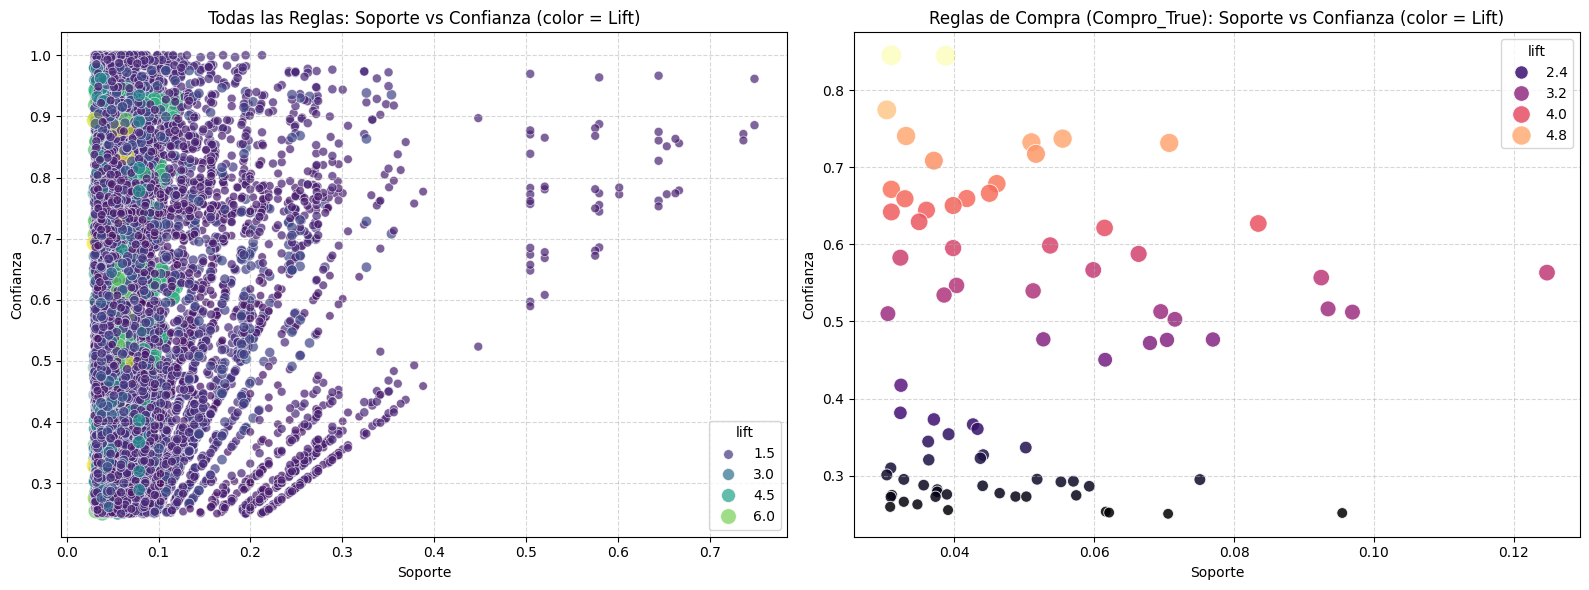

In [55]:
pd.set_option('display.max_colwidth', None)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafica de todas las reglas
sns.scatterplot(
    data=rules_all, x='support', y='confidence', hue='lift',
    palette='viridis', size='lift', sizes=(30, 150), alpha=0.7, ax=axes[0]
)
axes[0].set_title('Todas las Reglas: Soporte vs Confianza (color = Lift)')
axes[0].set_xlabel('Soporte')
axes[0].set_ylabel('Confianza')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfica de solo reglas que predicen Compra
sns.scatterplot(
    data=reglas_compra, x='support', y='confidence', hue='lift',
    palette='magma', size='lift', sizes=(60, 220), alpha=0.85, ax=axes[1]
)
axes[1].set_title('Reglas de Compra (Compro_True): Soporte vs Confianza (color = Lift)')
axes[1].set_xlabel('Soporte')
axes[1].set_ylabel('Confianza')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [56]:
top10_compra = reglas_compra.head(10).copy()

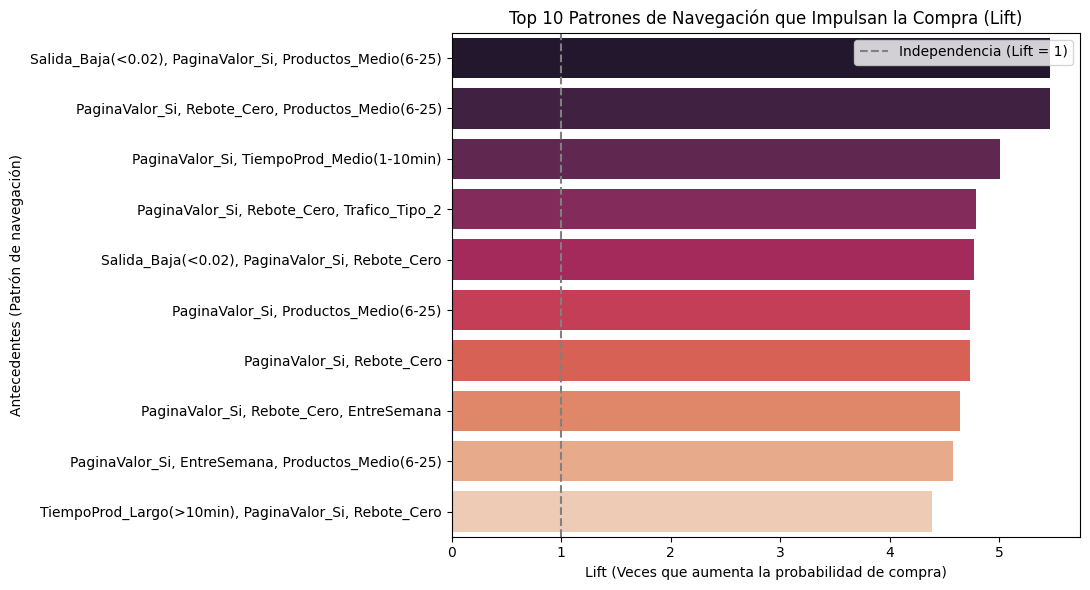

In [57]:
# Grafica de barras
plt.figure(figsize=(11, 6))
sns.barplot(data=top10_compra, x='lift', y='antecedents_str', palette='rocket')
plt.axvline(1, color='gray', linestyle='--', label='Independencia (Lift = 1)')
plt.title('Top 10 Patrones de Navegación que Impulsan la Compra (Lift)')
plt.xlabel('Lift (Veces que aumenta la probabilidad de compra)')
plt.ylabel('Antecedentes (Patrón de navegación)')
plt.legend()
plt.tight_layout()
plt.show()

In [58]:
tabla_final = top10_compra[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].copy()
tabla_final['support (%)'] = (tabla_final['support'] * 100).round(2)
tabla_final['confidence (%)'] = (tabla_final['confidence'] * 100).round(2)
tabla_final['lift'] = tabla_final['lift'].round(2)
display(tabla_final[['antecedents_str', 'consequents_str', 'support (%)', 'confidence (%)', 'lift']])

,antecedents_str,consequents_str,support (%),confidence (%),lift
2787,"Salida_Baja(<0.02), PaginaValor_Si, Productos_Medio(6-25)",Compro_True,3.10,84.51,5.46
2777,"PaginaValor_Si, Rebote_Cero, Productos_Medio(6-25)",Compro_True,3.88,84.45,5.46
302,"PaginaValor_Si, TiempoProd_Medio(1-10min)",Compro_True,3.03,77.43,5.00
2959,"PaginaValor_Si, Rebote_Cero, Trafico_Tipo_2",Compro_True,3.31,74.05,4.79
2929,"Salida_Baja(<0.02), PaginaValor_Si, Rebote_Cero",Compro_True,5.55,73.71,4.76
293,"PaginaValor_Si, Productos_Medio(6-25)",Compro_True,5.10,73.22,4.73
309,"PaginaValor_Si, Rebote_Cero",Compro_True,7.07,73.15,4.73
2949,"PaginaValor_Si, Rebote_Cero, EntreSemana",Compro_True,5.17,71.73,4.64
2802,"PaginaValor_Si, EntreSemana, Productos_Medio(6-25)",Compro_True,3.71,70.85,4.58
2867,"TiempoProd_Largo(>10min), PaginaValor_Si, Rebote_Cero",Compro_True,4.61,67.86,4.39
